# Phase 6: Maintenance decisions and simulated OEE

**Goal:** turn each engine's forecast into a maintenance action under crew limits, and compare three maintenance policies on a simulated plant.

> **Simulation, not measured results.** The forecasts are real model outputs; the plant, production and OEE are simulated with the study guide's assumptions.

Everything is computed by `python -m maintenance.run_phase6`; this notebook reads the saved results.

## Concepts in plain words

- **Alert threshold:** the point at which an engine is flagged for service. We use the *lower* edge of the 90% interval, so we act on the pessimistic estimate.
- **CP-SAT:** a solver for yes/no decisions under rules. Here: is engine e serviced on day d? Rules: each engine at most once, at most 3 services a day. It minimises a cost: late service is expensive, early service wastes some life, leaving an engine unserved is very expensive.
- **OEE:** availability (share of planned time running) x performance (output vs ideal speed) x quality (good units vs all units).
- **Policies:** run to failure (repair after breakdown), fixed interval (service every N cycles), predictive (service when the forecast says so).

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / 'docs' / 'figures'
CSV = {'float_precision': 'round_trip'}
res = json.loads((ROOT / 'maintenance/results_phase6.json').read_text())
snap = pd.read_csv(ROOT / 'maintenance/snapshot_decisions_phase6.csv', **CSV)
wo = pd.read_csv(ROOT / 'maintenance/work_orders_phase6.csv', **CSV)
mach = pd.read_csv(ROOT / 'maintenance/machines_phase6.csv', **CSV)
print('run', res['run_id'])
res['settings']

run phase6-618b9fbc3b7b


{'alert_threshold': 20,
 'risk_bins': [-1, 5, 10, 20],
 'horizon_days': 7,
 'crews_per_day': 3,
 'cycles_per_day': 2,
 'weights': {'late': 100, 'early': 1, 'unserved': 1000},
 'fixed_interval_percentile': 10}

## 6.1 Decision snapshot

Each test engine at its last observed cycle: forecast, alert, schedule, and what really happened (NASA's true remaining life).

In [2]:
cols = ['dataset', 'engine_id', 'cycle', 'rul_point', 'rul_low', 'rul_high', 'risk', 'service_day', 'true_rul', 'outcome']
snap[snap.flagged][cols].sort_values(['dataset', 'rul_low']).round(1)

,dataset,engine_id,cycle,rul_point,rul_low,rul_high,risk,service_day,true_rul,outcome
33,FD001,34,203,5.6,0.0,13.5,critical,0.0,7.0,serviced in time
80,FD001,81,213,7.4,1.2,13.5,critical,0.0,8.0,serviced in time
41,FD001,42,156,8.5,1.6,16.1,critical,0.0,10.0,serviced in time
81,FD001,82,162,8.4,2.3,15.1,critical,1.0,9.0,serviced in time
34,FD001,35,198,8.6,2.4,14.6,critical,1.0,11.0,serviced in time
30,FD001,31,196,10.1,4.9,14.6,critical,1.0,8.0,serviced in time
55,FD001,56,136,13.0,6.0,21.2,high,2.0,15.0,serviced in time
67,FD001,68,187,10.3,6.1,14.8,high,2.0,8.0,serviced in time
75,FD001,76,205,10.6,6.4,14.9,high,3.0,10.0,serviced in time
19,FD001,20,184,13.7,9.5,18.0,high,4.0,16.0,serviced in time


In [3]:
pd.crosstab(snap.dataset, snap.outcome)

outcome,"flagged, no crew in horizon","not flagged, healthy",serviced in time
dataset,,,
FD001,2,77,21
FD003,0,80,20


## 6.2 Three policies on the simulated plant

*Simulation, not measured results.*

In [4]:
rows = []
for ds, d in list(res['datasets'].items()) + [('Pooled', {'policies': res['pooled']})]:
    for p, s in d['policies'].items():
        rows.append({'dataset': ds, 'policy': p, **{k: s[k] for k in ('unplanned_failures', 'planned_services', 'downtime_hours', 'wasted_cycles', 'availability', 'performance', 'quality', 'oee')}})
tab = pd.DataFrame(rows)
tab.style.format({k: '{:.1%}' for k in ('availability', 'performance', 'quality', 'oee')})

,dataset,policy,unplanned_failures,planned_services,downtime_hours,wasted_cycles,availability,performance,quality,oee
0,FD001,Run to failure,100,0,4800.000000,0,97.2%,99.0%,98.6%,94.9%
1,FD001,Fixed interval,11,89,1240.000000,5317,99.0%,99.8%,98.9%,97.7%
2,FD001,Predictive,3,97,920.000000,2429,99.4%,99.8%,98.9%,98.1%
3,FD003,Run to failure,100,0,4800.000000,0,97.6%,99.2%,98.7%,95.5%
4,FD003,Fixed interval,10,90,1200.000000,7672,99.1%,99.8%,98.9%,97.9%
5,FD003,Predictive,5,95,1000.000000,2414,99.4%,99.8%,98.9%,98.2%
6,Pooled,Run to failure,200,0,9600.000000,0,97.4%,99.1%,98.7%,95.2%
7,Pooled,Fixed interval,21,179,2440.000000,12989,99.0%,99.8%,98.9%,97.8%
8,Pooled,Predictive,8,192,1920.000000,4843,99.4%,99.8%,98.9%,98.2%


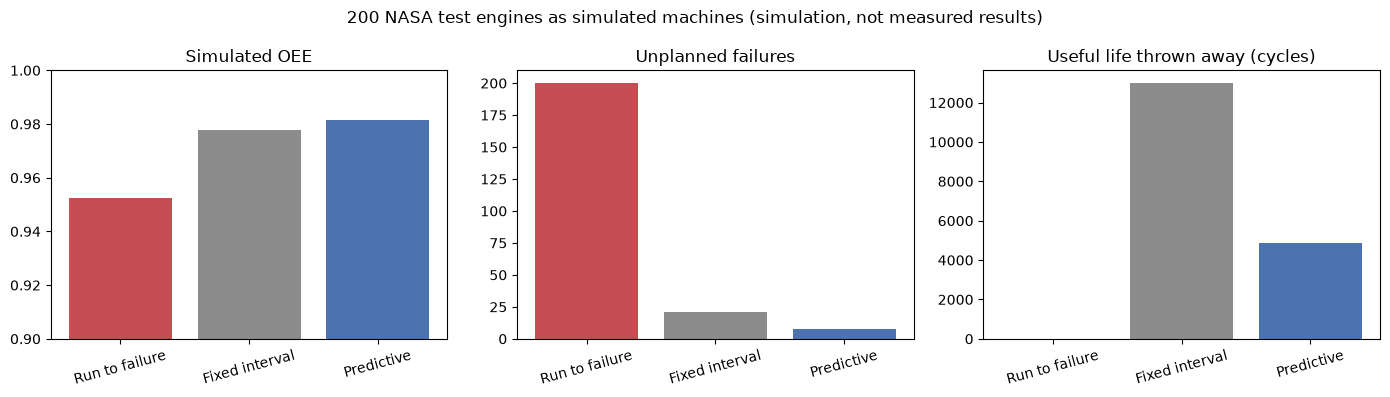

In [5]:
pool = tab[tab.dataset == 'Pooled'].set_index('policy')
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(axes, ['oee', 'unplanned_failures', 'wasted_cycles'],
                          ['Simulated OEE', 'Unplanned failures', 'Useful life thrown away (cycles)']):
    ax.bar(pool.index, pool[col], color=['#C44E52', '#8C8C8C', '#4C72B0'])
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=15)
axes[0].set_ylim(0.9, 1.0)
fig.suptitle('200 NASA test engines as simulated machines (simulation, not measured results)')
fig.tight_layout()
fig.savefig(FIG / 'phase6_policies.png', dpi=150, bbox_inches='tight')

In [6]:
pd.DataFrame({k: {'gap (OEE points)': round(v['diff'] * 100, 2), '95% interval': f"{v['ci'][0] * 100:+.2f} to {v['ci'][1] * 100:+.2f}"} for k, v in res['pooled_gaps'].items()}).T

,gap (OEE points),95% interval
Predictive - Run to failure,2.93,+2.80 to +3.05
Predictive - Fixed interval,0.37,+0.19 to +0.56


## 6.3 Sensitivity (nothing is chosen from this)

In [7]:
pd.DataFrame([{'dataset': ds, 'change': k, **{p: round(v[p]['oee'] * 100, 2) for p in v}, 'predictive failures': v['Predictive']['unplanned_failures']}
              for ds, d in res['datasets'].items() for k, v in d['sensitivity'].items()])

,dataset,change,Run to failure,Fixed interval,Predictive,predictive failures
0,FD001,threshold 10,94.93,97.71,97.86,5
1,FD001,threshold 30,94.93,97.71,98.34,1
2,FD001,2 crews,94.93,97.71,98.12,3
3,FD001,4 crews,94.93,97.71,98.12,3
4,FD001,late weight 10,94.93,97.71,98.12,3
5,FD001,failure downtime 24 h,96.29,97.92,98.17,3
6,FD001,failure downtime 96 h,92.33,97.30,98.02,3
7,FD003,threshold 10,95.51,97.87,98.04,6
8,FD003,threshold 30,95.51,97.87,98.47,0
9,FD003,2 crews,95.51,97.87,98.22,5


## 6.4 One machine, end to end

The full traces are in `docs/MAINTENANCE_OEE.md`; here is one work order and its outcome.

In [8]:
e = int(snap.loc[snap.rul_low.idxmin(), 'engine_id']); ds = snap.loc[snap.rul_low.idxmin(), 'dataset']
display(wo[(wo.dataset == ds) & (wo.engine_id == e)].T)
mach[(mach.dataset == ds) & (mach.machine == e)].set_index('policy')[['life', 'run_cycles', 'event', 'wasted_cycles', 'downtime_hours', 'good_units', 'planned_hours']]

,65
engine_id,34
created_day,92
created_cycle,184
day,98
service_cycle,196
rul_low,17.020942
rul_point,24.642523
forecast_cycle,184
forecast_age,0
risk,medium


,life,run_cycles,event,wasted_cycles,downtime_hours,good_units,planned_hours
policy,,,,,,,
Run to failure,210,210,failure,0,48.0,16416.0,1728.0
Fixed interval,210,154,service,56,8.0,12196.8,1240.0
Predictive,210,196,service,14,8.0,15458.4,1576.0


## What the results say

1. **Decision snapshot.** At each engine's last observed cycle, 23 FD001 and 20 FD003 engines are flagged on the lower bound. FD001 needs more services than the 21 crew slots of the week, so CP-SAT books 21 and leaves 2 (with more than a week of true life left) for the next plan. Both plans are optimal (proved again with the Hungarian algorithm) and no booked engine fails first.
2. **Policies (simulated, 200 machines).** OEE: run to failure 95.2%, fixed interval 97.8%, predictive 98.2%. Unplanned failures 200 / 21 / 8; useful life thrown away 0 / 12,989 / 4,843 cycles.
3. **The gain over a fixed interval is small but consistent:** +0.37 OEE points (95% interval +0.19 to +0.56), and predictive stays ahead in every sensitivity run. Most of its value is in failures avoided and life not wasted, which a single OEE figure understates.
4. **Remaining failures are explained, not hidden:** all 8 predictive-policy failures happen after the engine's NASA data ends, after the last forecast's lower bound had already missed the truth.
5. **Honest limits:** the plant is a simulation with the guide's assumptions; a higher alert threshold looks better here but is not adopted, because picking it from these results would tune on the test engines.

## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Re-checked the Phase 5 forecasts before using them | Decisions are only as good as their inputs | All 200 forecasts are valid; the published model was rebuilt and matched exactly | Phase 7 can score new shifts with the same model |
| 2 | Alert on the interval's lower bound | Acting on the pessimistic edge protects against late predictions | The bound flags engines early enough that no booked engine fails first | Alerts in the Prefect flow use the same rule |
| 3 | CP-SAT schedule with an independent optimality proof | Crews are limited; a solver's word is not evidence | Both snapshot plans are optimal; the guide's cost breaks if the late weight exceeds the unserved penalty | Weights stay as documented assumptions with that caveat |
| 4 | Simulated plant with written assumptions | NASA data has no production records | OEE = availability x performance x quality, checked against good / (rate x planned) | Phase 8 dashboards read these fact_oee rows |
| 5 | Three policies on the same 200 machines | The business case needs a fair comparison | Predictive wins on failures, wasted life and OEE, but its OEE edge over a fixed interval is small | The resume bullet quotes failures and wasted life, not only OEE |
| 6 | Traced engines from raw sensor to OEE | Every displayed action must lead back to its forecast | Values stay consistent at every stage; the database enforces the alert-to-forecast link | Dashboards can drill from an alert to its forecast |
| 7 | Sensitivity runs, not tuning | Assumptions are guesses; the test set must not choose them | Crew count barely matters in the replay; the alert threshold matters most | A threshold choice belongs on validation engines in a later phase |
